# Baseline de classification avec Scikit-Learn

L'objectif de ce notebook est de construire un premier modèle de référence permettant d'obtenir un point de comparaison pour les futurs modèles de Deep Learning.

Conformément au protocole expérimental défini précédemment :

- les données d'entraînement sont utilisées pour apprendre le modèle ;
- les performances sont mesurées sur l'ensemble de validation ;
- le jeu de test reste inutilisé.

# Chargement des bibliothèques

In [59]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
)

# Reproductibilité

In [60]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print(f"Seed fixée : {SEED}")

Seed fixée : 42


# Chargement des données préparées

In [61]:
x_train = np.load("../data/processed/x_train.npy")
y_train = np.load("../data/processed/y_train.npy")

x_val = np.load("../data/processed/x_val.npy")
y_val = np.load("../data/processed/y_val.npy")

In [62]:
print(x_train.shape)
print(y_train.shape)

print(x_val.shape)
print(y_val.shape)

(54000, 28, 28)
(54000,)
(6000, 28, 28)
(6000,)


# Choix du modèle de référence

Le sujet autorise l'utilisation d'une régression logistique ou d'une forêt aléatoire comme modèle de référence.

Nous retenons la régression logistique pour plusieurs raisons :

- elle constitue une baseline classique pour les problèmes de classification ;
- elle est rapide à entraîner sur MNIST ;
- elle nécessite peu d'hyperparamètres ;
- elle fournit un point de comparaison simple avant l'utilisation de réseaux de neurones ;
- ses performances sont généralement suffisantes pour mettre en évidence le gain apporté ultérieurement par les architectures MLP et CNN.

L'objectif de cette baseline n'est pas d'obtenir les meilleures performances possibles mais de disposer d'un modèle de référence reproductible permettant d'évaluer les améliorations apportées par les modèles plus complexes.

# Préparation des données pour Scikit-Learn

Les modèles Scikit-Learn attendent des données tabulaires sous la forme :

(n_samples, n_features)

Les images 28 × 28 pixels doivent donc être transformées en vecteurs de 784 caractéristiques.

## Mise à plat des images

In [63]:
x_train_flat = x_train.reshape(x_train.shape[0], -1)

x_val_flat = x_val.reshape(x_val.shape[0], -1)

print("Train :", x_train_flat.shape)
print("Validation :", x_val_flat.shape)

Train : (54000, 784)
Validation : (6000, 784)


# Analyse

Les images ont été correctement transformées en vecteurs de 784 caractéristiques.

Cette représentation est adaptée aux modèles classiques de Machine Learning proposés par Scikit-Learn.

Contrairement aux futurs CNN, la régression logistique ne travaille pas directement sur la structure spatiale des images et considère chaque pixel comme une caractéristique indépendante.

# Vérification des données

Les données ont été chargées avec succès.

Les ensembles utilisés pour cette expérimentation sont :

- entraînement : 54 000 images ;
- validation : 6 000 images.

Le jeu de test reste volontairement inutilisé conformément au protocole expérimental défini précédemment.

Les images ont été transformées en vecteurs de 784 caractéristiques afin d'être compatibles avec la régression logistique de Scikit-Learn.

# Conclusion intermédiaire

Les données sont maintenant compatibles avec les algorithmes Scikit-Learn.

Le prochain objectif consiste à entraîner une régression logistique sur l'ensemble d'entraînement puis à évaluer ses performances sur l'ensemble de validation.

# Choix de l'algorithme

Deux modèles étaient envisagés pour la baseline :

- Régression logistique ;
- Forêt aléatoire.

La régression logistique a été retenue car elle constitue une référence classique pour la classification sur MNIST et permet une comparaison claire avec les futurs modèles de Deep Learning.

Afin de sélectionner automatiquement un niveau de régularisation adapté, nous utilisons la version `LogisticRegressionCV` de Scikit-Learn qui réalise une validation croisée interne sur les données d'entraînement.

# Entraînement du modèle

Nous entraînons une régression logistique avec validation croisée interne afin de sélectionner automatiquement le coefficient de régularisation le plus adapté.

L'entraînement est réalisé exclusivement sur l'ensemble d'entraînement.

L'ensemble de validation reste indépendant et servira à évaluer les performances du modèle.

# Choix du nombre de folds

La validation croisée nécessite de définir le nombre de sous-ensembles (folds) utilisés pour l'estimation des performances.

Les valeurs couramment rencontrées sont :
- 3 folds ;
- 5 folds ;
- 10 folds.

Dans ce projet, une validation croisée à 5 folds est retenue.

Ce choix représente un compromis entre :

- stabilité de l'estimation ;
- coût de calcul ;
- temps d'entraînement.

Cette valeur constitue également un standard largement utilisé dans la littérature et les bibliothèques de Machine Learning.

# Paramétrage du modèle

La régression logistique est entraînée à l'aide d'une validation croisée à 5 folds.

Les principaux paramètres retenus sont :

- `cv=5` : sélection automatique du coefficient de régularisation à l'aide d'une validation croisée ;
- `random_state=42` : reproductibilité des résultats ;
- `max_iter=1000` : augmentation du nombre maximal d'itérations afin de favoriser la convergence ;
- `n_jobs=-1` : utilisation de tous les cœurs disponibles pour accélérer l'entraînement.

In [64]:
from sklearn.linear_model import LogisticRegressionCV

Le problème MNIST comporte dix classes.

Dans la version de Scikit-Learn utilisée pour ce projet (1.9.1), la gestion multi-classe est directement intégrée à LogisticRegressionCV. Aucune stratégie One-vs-Rest n'est configurée manuellement.

Le solveur LBFGS est retenu car il est adapté à la régression logistique multi-classe et constitue également le choix recommandé par défaut dans Scikit-Learn.

In [65]:
baseline_model = LogisticRegressionCV(
    cv=5,
    solver="lbfgs",
    random_state=SEED,
    max_iter=1000,
    n_jobs=-1,
)

In [66]:
try:
    baseline_model.fit(
        x_train_flat,
        y_train,
    )
    print("Entraînement terminé ✅")
except Exception as e:
    print("Erreur :", e)

/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressio

Entraînement terminé ✅


In [67]:
print("Entraînement terminé ✅")

print("Meilleure valeur de C :", baseline_model.C_[0])

Entraînement terminé ✅
Meilleure valeur de C : 0.3593813663804626


# Résultat de la validation croisée

La validation croisée a sélectionné automatiquement une valeur du coefficient de régularisation :

Cette valeur correspond au meilleur compromis observé entre capacité de généralisation et complexité du modèle.

L'utilisation de LogisticRegressionCV permet ainsi d'éviter un choix manuel du paramètre de régularisation et d'obtenir une baseline plus robuste et reproductible. 

# Prédiction sur l'ensemble de validation.

Le modèle entrainé est maintenant évalué sur l'ensemble de validation. 

Conformément au protocole expérimental, le jeu de test n'est pas utilisé à ce stade.

In [68]:
y_val_pred = baseline_model.predict(x_val_flat)

In [69]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
)

## Calcul des métriques

In [70]:
accuracy = accuracy_score(
    y_val,
    y_val_pred,
)

precision = precision_score(
    y_val,
    y_val_pred,
    average="macro",
)

recall = recall_score(
    y_val,
    y_val_pred,
    average="macro",
)

f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro",
)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

Accuracy  : 0.9222
Precision : 0.9215
Recall    : 0.9212
F1-score  : 0.9213


# Analyse des performances

Les performances obtenues sur l'ensemble de validation sont les suivantes :

| Métrique | Valeur |
|-----------|-----------|
| Accuracy | 92,22 % |
| Precision macro | 92,15 % |
| Recall macro | 92,12 % |
| F1-score macro | 92,13 % |

Les quatre métriques présentent des valeurs très proches, ce qui est cohérent avec l'équilibre des classes observé lors de l'analyse exploratoire.

Les résultats montrent qu'une régression logistique est capable de capturer une partie importante de l'information contenue dans les pixels des images manuscrites.

Toutefois, les performances restent limitées par la nature du modèle. La régression logistique considère chaque pixel indépendamment et ne tient pas compte des structures spatiales présentes dans les images.

Cette baseline fournit ainsi un point de comparaison pertinent pour évaluer les gains futurs apportés par les architectures MLP et CNN.


# Conclusion BASELINE-01

Une baseline de classification fondée sur une régression logistique a été mise en place avec succès.

La validation croisée a sélectionné automatiquement un coefficient de régularisation de :

```text
C = 0.3594

Le modèle atteint une accuracy de 92,22 % surl'ensemble de validation. 

Ce résulat constitue la référence de départ ui servira de comparaison pour l'ensemble des expérimentations utltérieures. 

# Sauvegarde des résultats

Le modèle entraîné ainsi que les métriques obtenues sont sauvegardés afin de garantir la reproductibilité des expériences et de faciliter les comparaisons avec les futurs modèles MLP et CNN.

In [71]:
from joblib import dump

In [72]:
dump(
    baseline_model,
    "../data/models/baseline_logistic_regression.joblib",
)

['../data/models/baseline_logistic_regression.joblib']

In [73]:
import os

print(os.path.exists("../data/models/baseline_logistic_regression.joblib"))

True


In [74]:
baseline_results = {
    "model": "LogisticRegressionCV",
    "best_C": float(baseline_model.C_[0]),
    "accuracy": float(accuracy),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(f1),
}

In [75]:
import json

with open(
    "../reports/experiments/baseline_results.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        baseline_results,
        file,
        indent=4,
    )

In [76]:
results_df = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
        ],
        "Value": [
            accuracy,
            precision,
            recall,
            f1,
        ],
    }
)

results_df

,Metric,Value
0,Accuracy,0.922167
1,Precision,0.921482
2,Recall,0.921201
3,F1-score,0.921280


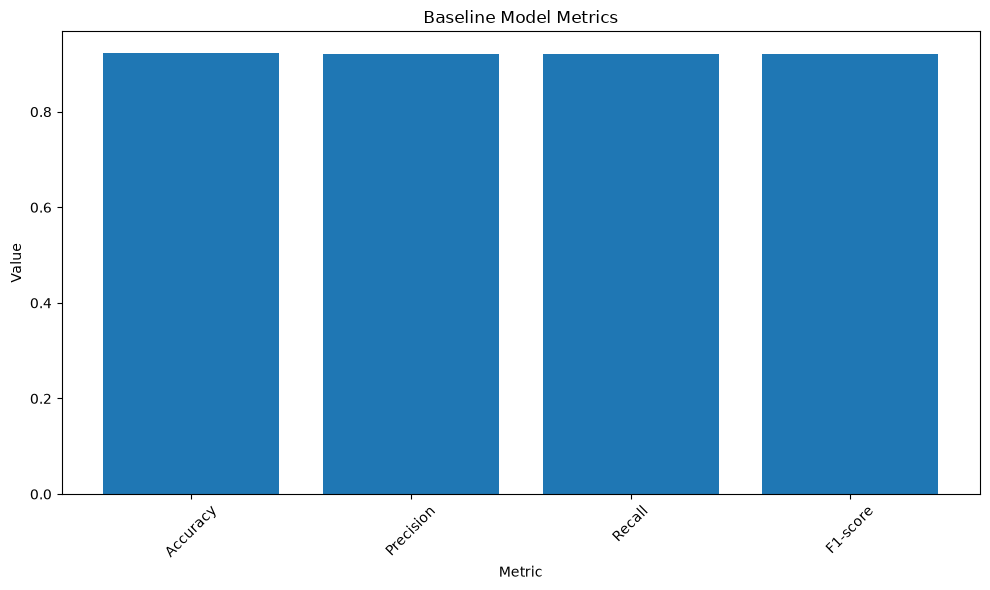

In [77]:
results_df.to_csv(
    "../reports/experiments/baseline_metrics.csv",
    index=False,
)

plt.figure(figsize=(10, 6))
plt.bar(results_df["Metric"], results_df["Value"])
plt.title("Baseline Model Metrics")
plt.xlabel("Metric")
plt.ylabel("Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../reports/figures/baseline_metrics.png")
plt.show()

# Analyse de la matrice de confusion

La matrice de confusion permet d'étudier plus finement le comportement du modèle.

Deux représentations seront utilisées :

- une matrice brute représentant le nombre d'exemples classés dans chaque catégorie ;
- une matrice normalisée représentant les proportions de classification.

La matrice brute facilite l'identification du volume réel d'erreurs tandis que la matrice normalisée permet de comparer équitablement les performances entre les classes.